# 5s7s10s Fly: Rolling PCA Rich / Cheap

A rolling 3-factor PCA of the USD swap curve gives a fair value for the 5s7s10s fly (2 × 7y − 5y − 10y). The **residual** (actual − fair value) is the rich/cheap signal. The notebook z-scores it, checks whether it mean-reverts, builds PC-neutral weights, and runs a simple backtest.

> **No look-ahead.** Every estimate at date *t* uses data in [t − WINDOW, t] only, and a truncation test asserts this.
>
> **The data file is simulated**, so the results test the code only. **No carry or roll yet**: the hook is marked in the backtest.

## Parameters

In [1]:
DATA_PATH       = "sofr_swap_rates_simulated.csv"
TENORS_WANTED   = [2, 3, 4, 5, 7, 10, 12, 15, 20, 30]   # whatever subset exists is used
WINDOW          = 500          # business days in each PCA window
N_PCS           = 3
Z_LOOKBACK      = 250          # past out-of-sample residuals used for the z-score
Z_ENTRY         = 2.0
FLY             = {5: -1, 7: 2, 10: -1}
MAX_HOLD        = 60           # days
COST_BP_PER_LEG = 0.25         # bp per leg per side, scaled by |weight| (fly-bp units)
EXEC_LAG        = 1            # signal at close t, trade at close t+1
STALE_RUN       = 3            # flag values unchanged for this many days in a row
OUTLIER_SD      = 6            # flag daily changes beyond this many sd
FV_JUMP_BP      = 0.5          # flag FV changes from re-estimation above this
SEED            = 11

In [2]:
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

pd.set_option("display.width", 150)
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948"
C_INK, C_MUTED, C_GREY = "#0b0b0b", "#52514e", "#b8b7b0"
plt.rcParams.update({"figure.figsize": (11, 3.6), "figure.dpi": 100, "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": "#e6e5e0", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.titleweight": "bold", "axes.titlesize": 12,
                     "legend.frameon": False, "xtick.color": C_MUTED, "ytick.color": C_MUTED, "axes.labelcolor": C_MUTED})

## 1. Data

**The file:** `sofr_swap_rates_simulated.csv`, one row per date (ISO `YYYY-MM-DD`). There is one column per tenor, labelled `3y` … `30y`, with rates in percent, at daily business-day frequency. There is **no 2y column**, so 3y stands in for it in the PC2 sign rule.

**The loader:**
1. Parses dates, sorts them, and drops weekends and duplicate dates.
2. Keeps the wanted tenors that exist.
3. Converts to bp. Decimals are ×10,000 and percent is ×100, detected from the median |rate|.
4. Drops rows with any missing tenor.
5. **Flags, but does not drop,** stale values and outliers. A value is stale when it is unchanged for `STALE_RUN` or more days in a row. An outlier is a daily change beyond `OUTLIER_SD` sd, using a full-sample sd; that is a data-quality check only and isn't used in the signal.
6. Checks for a LIBOR/SOFR mix and keeps SOFR-only dates if it finds one.

In [3]:
def detect_libor_sofr(raw, path):
    # Look for an explicit curve/index column; otherwise infer from column names and the file name.
    text_cols = [c for c in raw.columns if raw[c].dtype == object or str(raw[c].dtype).startswith("str")]
    for c in text_cols:
        vals = raw[c].astype(str).str.upper()
        if vals.str.contains("LIBOR").any() or vals.str.contains("SOFR").any():
            is_sofr = vals.str.contains("SOFR")
            if (~is_sofr).any() and is_sofr.any():
                print(f"[FLAG] column '{c}' mixes LIBOR and SOFR: keeping SOFR-only rows ({int(is_sofr.sum())}).")
            return is_sofr.values
    names = " ".join(map(str, raw.columns)).upper() + " " + path.upper()
    if "LIBOR" in names and "SOFR" in names:
        print("[FLAG] both LIBOR and SOFR appear in labels: check the history manually.")
    elif "LIBOR" in names:
        print("[FLAG] history labelled LIBOR: no SOFR-only dates to keep.")
    else:
        print("LIBOR/SOFR: no index column or LIBOR label found; file is labelled SOFR -> treated as SOFR throughout.")
    return np.ones(len(raw), bool)


def to_bp(df):
    med = float(np.nanmedian(df.abs().values))
    if med < 0.25:
        return df * 1e4, f"decimals (median {med:.4f}) -> x10,000"
    if med < 25:
        return df * 100, f"percent (median {med:.2f}) -> x100"
    return df, f"bp (median {med:.0f}) -> unchanged"


def load_curve(path=DATA_PATH):
    raw = pd.read_csv(path)
    keep = detect_libor_sofr(raw, path)
    raw = raw[keep]
    date_col = raw.columns[0]
    raw.index = pd.to_datetime(raw.pop(date_col))
    raw = raw.rename(columns=lambda c: int(float(str(c).lower().rstrip("y"))) if str(c).lower().rstrip("y").replace(".", "").isdigit() else c)
    tenors = [t for t in TENORS_WANTED if t in raw.columns]
    df = raw[tenors].apply(pd.to_numeric, errors="coerce").sort_index()
    n0 = len(df)
    df = df[~df.index.duplicated(keep="last")]
    weekend = df.index.dayofweek >= 5
    df = df[~weekend]
    df, unit_note = to_bp(df)
    missing = df.isna().any(axis=1)
    df = df.dropna()
    df.index.name, df.columns.name = "date", "tenor"

    d = df.diff()
    stale = (d == 0).astype(int).rolling(STALE_RUN - 1).sum() == STALE_RUN - 1   # STALE_RUN equal values in a row
    outlier = d.abs() > OUTLIER_SD * d.std()
    print(f"Columns in file: {list(raw.columns)}")
    print(f"Tenors used: {tenors}  (missing from wanted list: {[t for t in TENORS_WANTED if t not in tenors]})")
    print(f"Units: {unit_note} | dates: {df.index[0]:%Y-%m-%d} to {df.index[-1]:%Y-%m-%d}, "
          f"median gap {df.index.to_series().diff().dt.days.median():.0f} day(s)")
    print(f"Rows: {n0} read, {int(weekend.sum())} weekend, {int(missing.sum())} with missing tenors dropped -> {len(df)}")
    print(f"Flags: {int(stale.values.sum())} stale values ({STALE_RUN}+ days unchanged), "
          f"{int(outlier.values.sum())} outliers (|change| > {OUTLIER_SD} sd)")
    return df, stale, outlier


y, stale_flags, outlier_flags = load_curve()
TENORS = list(y.columns)
w = pd.Series(0.0, index=TENORS); w[list(FLY)] = list(FLY.values())     # fly weights on the full tenor vector
F = y @ w                                                               # actual fly, bp
y.describe().loc[["mean", "std", "min", "max"]].round(1)

LIBOR/SOFR: no index column or LIBOR label found; file is labelled SOFR -> treated as SOFR throughout.
Columns in file: [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 20, 25, 30]
Tenors used: [3, 4, 5, 7, 10, 12, 15, 20, 30]  (missing from wanted list: [2])
Units: percent (median 2.61) -> x100 | dates: 2016-01-04 to 2025-12-31, median gap 1 day(s)
Rows: 2608 read, 0 weekend, 0 with missing tenors dropped -> 2608
Flags: 0 stale values (3+ days unchanged), 0 outliers (|change| > 6 sd)


tenor,3,4,5,7,10,12,15,20,30
mean,256.4,269.0,278.0,287.4,294.2,295.0,294.3,291.4,280.7
std,133.8,130.2,127.0,123.7,119.1,116.0,111.7,108.2,99.3
min,6.1,17.3,30.3,44.0,52.5,63.4,70.2,84.5,106.0
max,543.7,534.9,539.0,549.6,551.8,546.0,540.9,521.0,491.0


## 2. Rolling PCA, fair value and residual

At each date *t* from `WINDOW` onward, using data in [t − WINDOW, t] only:

1. **Loadings.** Take the covariance of daily bp changes (covariance, not correlation), eigen-decompose it and keep the top 3 eigenvectors, E3.
2. **Align the PCs.** First, match them to the previous window's PCs by absolute correlation, in case two PCs swap order. Then fix the signs:
   - PC1 has a positive mean loading;
   - PC2 has loading(30y) − loading(shortest tenor) > 0;
   - PC3 has a positive loading at 7y.
3. **Fair curve.** μ = the mean level over the window. The scores are s = E3ᵀ(y_t − μ), and the reconstructed curve is ŷ = μ + E3 s.
4. **Residual.** FV = wᵀŷ, and the residual is r = F − FV. Positive means the belly is cheap.
5. **Store.** Keep r, the explained variance, the loadings, the fly's betas to each PC (b_k = wᵀe_k), and FV re-evaluated with the previous window's estimates, for the stability check.

In [4]:
def pca_window(levels, k=N_PCS):
    # levels: (WINDOW+1) x m block of levels. Returns top-k eigenvectors of the covariance of daily changes, variance shares, mean level.
    vals, vecs = np.linalg.eigh(np.cov(np.diff(levels, axis=0), rowvar=False))
    order = np.argsort(vals)[::-1]
    return vecs[:, order[:k]], vals[order] / vals.sum(), levels.mean(axis=0)


def align(E, ratio, E_prev, tenors):
    # Reorder to best match the previous window (max total |corr|), then apply the sign rules.
    swapped = False
    if E_prev is not None:
        perms = list(itertools.permutations(range(E.shape[1])))
        score = [sum(abs(np.corrcoef(E[:, p[j]], E_prev[:, j])[0, 1]) for j in range(E.shape[1])) for p in perms]
        best = perms[int(np.argmax(score))]
        swapped = best != tuple(range(E.shape[1]))
        E, ratio = E[:, best], np.r_[ratio[list(best)], ratio[E.shape[1]:]]
    i7, i_short, i30 = tenors.index(7), 0, tenors.index(max(tenors))
    if E[:, 0].mean() < 0: E[:, 0] *= -1
    if E[i30, 1] - E[i_short, 1] < 0: E[:, 1] *= -1
    if E.shape[1] > 2 and E[i7, 2] < 0: E[:, 2] *= -1
    return E, ratio, swapped


def rolling_pca(levels, fly_w):
    Y, wv = levels.values, fly_w.values
    n, m = Y.shape
    out = {k: np.full(n, np.nan) for k in ["resid", "fv", "fv_prev_est"]}
    expl, betas = np.full((n, N_PCS), np.nan), np.full((n, N_PCS), np.nan)
    loadings = np.full((n, m, N_PCS), np.nan)
    swaps, E_prev, mu_prev = 0, None, None
    for t in range(WINDOW, n):
        E, ratio, mu = pca_window(Y[t - WINDOW: t + 1])            # rows t-WINDOW .. t: nothing after t
        E, ratio, sw = align(E, ratio, E_prev, list(levels.columns))
        swaps += sw
        yhat = mu + E @ (E.T @ (Y[t] - mu))                         # scores -> reconstructed curve
        out["fv"][t] = wv @ yhat
        out["resid"][t] = wv @ Y[t] - out["fv"][t]
        if E_prev is not None:                                      # same day t, previous window's estimates
            out["fv_prev_est"][t] = wv @ (mu_prev + E_prev @ (E_prev.T @ (Y[t] - mu_prev)))
        expl[t], betas[t], loadings[t] = ratio[:N_PCS], wv @ E, E
        E_prev, mu_prev = E, mu
    idx, pcs = levels.index, [f"PC{i+1}" for i in range(N_PCS)]
    res = pd.DataFrame(out, index=idx)
    res["fly"] = levels.values @ wv
    return res, pd.DataFrame(expl, idx, pcs), pd.DataFrame(betas, idx, pcs), loadings, swaps


def zscores(r, lb=Z_LOOKBACK):
    # z_t vs the previous lb residuals only (shift(1)); MAD version uses median and 1.4826*MAD.
    roll = r.rolling(lb, min_periods=lb)
    mean, sd = roll.mean().shift(1), roll.std().shift(1)
    med = roll.median().shift(1)
    mad = r.rolling(lb, min_periods=lb).apply(lambda x: np.median(np.abs(x - np.median(x))), raw=True).shift(1) * 1.4826
    return pd.DataFrame({"z": (r - mean) / sd, "z_mad": (r - med) / mad, "band_mid": mean, "band_sd": sd})


res, expl, betas, loadings, n_swaps = rolling_pca(y, w)
res = res.join(zscores(res["resid"]))
valid = res["z"].dropna().index
print(f"Residuals from {res['resid'].first_valid_index():%Y-%m-%d}; z-scores from {valid[0]:%Y-%m-%d} ({len(valid)} days)")
print(f"PC order swaps corrected by matching: {n_swaps}")

Residuals from 2017-12-04; z-scores from 2018-11-19 (1858 days)
PC order swaps corrected by matching: 0


### No-look-ahead test

The test cuts the data at a random date *t* and reruns everything. Every residual and z-score up to *t* must be unchanged.

In [5]:
rng = np.random.default_rng(SEED)
t_cut = int(rng.integers(y.index.get_loc(valid[0]), len(y) - 1))
res_cut = rolling_pca(y.iloc[: t_cut + 1], w)[0]
res_cut = res_cut.join(zscores(res_cut["resid"]))
past = y.index[: t_cut + 1]
for col in ["resid", "fv", "z", "z_mad"]:
    assert np.allclose(res.loc[past, col], res_cut[col], atol=1e-9, equal_nan=True), f"look-ahead in {col}"
print(f"[PASS] truncated at {y.index[t_cut]:%Y-%m-%d}: all {res_cut['resid'].notna().sum()} past residuals and z-scores unchanged.")

[PASS] truncated at 2019-10-31: all 499 past residuals and z-scores unchanged.


## 3. PCA diagnostics

What to expect, and what the fly's betas mean:

- **Variance explained:** PC1 should explain most of it, roughly 85–90%.
- **Loading shapes:** level should be flat, slope should rise from the short end to the long end, and curvature should have the belly against the wings.
- **Fly betas:** they show how much each factor still moves the unweighted 1:2:1 fly.

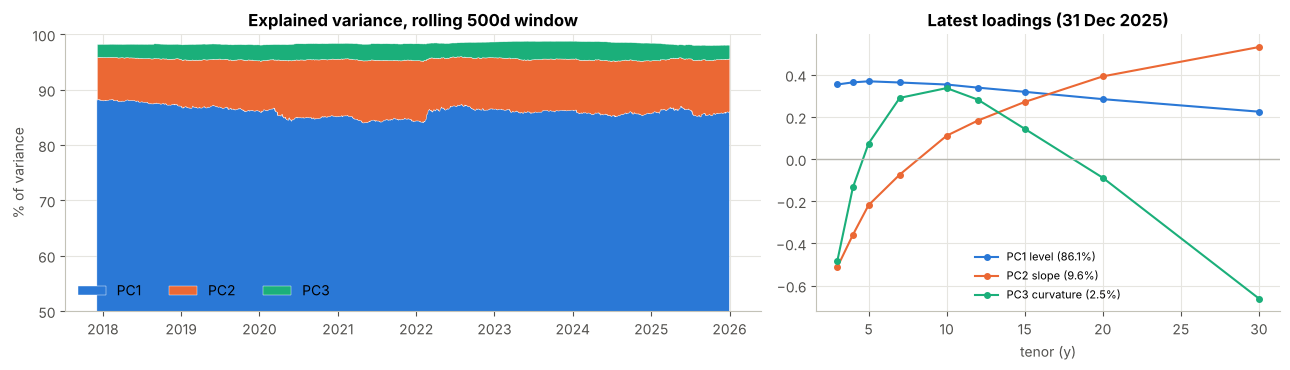

Latest fly betas to PCs (b_k = w'e_k): {'PC1': 0.004, 'PC2': -0.039, 'PC3': 0.17}


In [6]:
E_last = loadings[-1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
e = expl.dropna() * 100
a1.stackplot(e.index, e.T.values, colors=[C_BLUE, C_ORANGE, C_AQUA], labels=e.columns, edgecolor="white", lw=0.3)
a1.set_ylim(50, 100); a1.set_ylabel("% of variance"); a1.legend(loc="lower left", ncol=3)
a1.set_title(f"Explained variance, rolling {WINDOW}d window")
for j, (col, nm) in enumerate(zip([C_BLUE, C_ORANGE, C_AQUA], ["level", "slope", "curvature"])):
    a2.plot(TENORS, E_last[:, j], marker="o", ms=4, color=col, label=f"PC{j+1} {nm} ({expl.iloc[-1, j]:.1%})")
a2.axhline(0, color=C_GREY, lw=1); a2.set_xlabel("tenor (y)"); a2.legend(fontsize=8)
a2.set_title(f"Latest loadings ({y.index[-1]:%d %b %Y})")
plt.tight_layout(); plt.show()
print("Latest fly betas to PCs (b_k = w'e_k):", betas.iloc[-1].round(3).to_dict())

## 4. Fly vs fair value, residual and z-score

The charts below show:

- the actual fly against its fair value;
- the residual, with ±2 sd bands from the previous `Z_LOOKBACK` residuals;
- the z-score, both the standard version and a robust version (median and MAD instead of mean and sd), with the entry zones shaded.

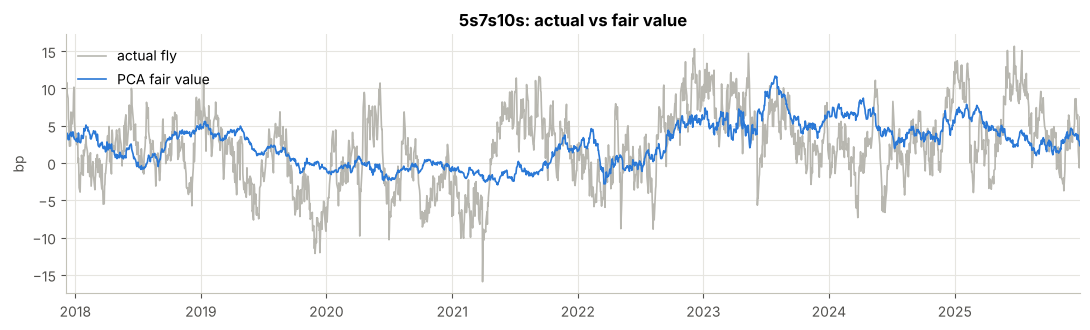

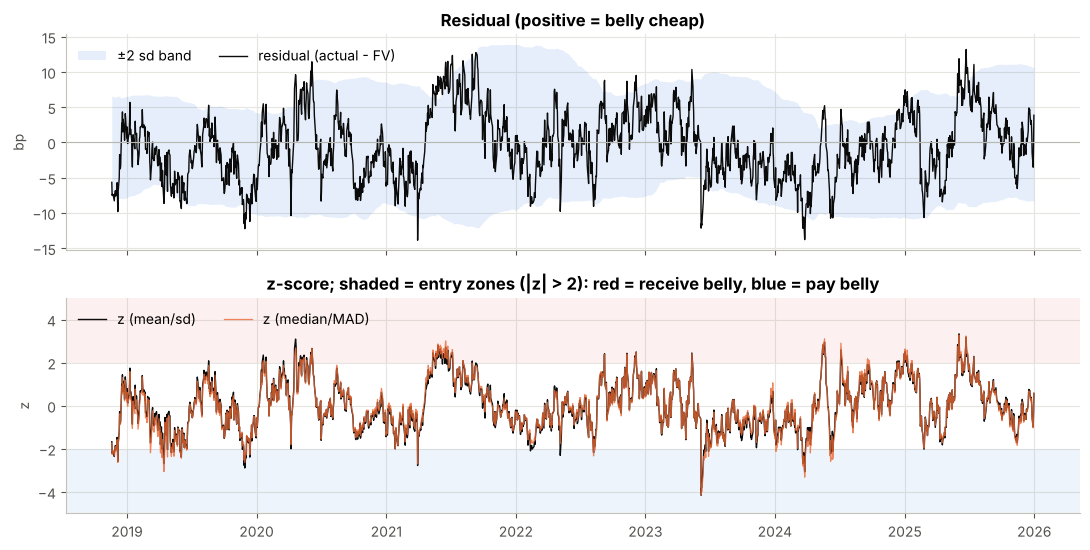

In [7]:
v = res.loc[valid]
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(res.index, res["fly"], color=C_GREY, lw=1.2, label="actual fly")
ax.plot(res.index, res["fv"], color=C_BLUE, lw=1.2, label="PCA fair value")
ax.set_ylabel("bp"); ax.legend(loc="upper left"); ax.set_title("5s7s10s: actual vs fair value")
ax.set_xlim(res["fv"].first_valid_index(), res.index[-1])
plt.tight_layout(); plt.show()

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
a1.fill_between(v.index, v.band_mid - 2 * v.band_sd, v.band_mid + 2 * v.band_sd, color=C_BLUE, alpha=0.12, lw=0, label="±2 sd band")
a1.plot(v.index, v.resid, color=C_INK, lw=1, label="residual (actual - FV)")
a1.axhline(0, color=C_GREY, lw=0.8); a1.set_ylabel("bp"); a1.legend(loc="upper left", ncol=2)
a1.set_title("Residual (positive = belly cheap)")
a2.axhspan(Z_ENTRY, 6, color=C_RED, alpha=0.08, lw=0); a2.axhspan(-6, -Z_ENTRY, color=C_BLUE, alpha=0.08, lw=0)
a2.plot(v.index, v.z, color=C_INK, lw=1, label="z (mean/sd)")
a2.plot(v.index, v.z_mad, color=C_ORANGE, lw=0.9, alpha=0.8, label="z (median/MAD)")
a2.set_ylim(-5, 5); a2.set_ylabel("z"); a2.legend(loc="upper left", ncol=2)
a2.set_title(f"z-score; shaded = entry zones (|z| > {Z_ENTRY:g}): red = receive belly, blue = pay belly")
plt.tight_layout(); plt.show()

## 5. Mean reversion

This fits an AR(1), r_t = c + φ r_{t−1} + ε, to the stored out-of-sample residuals and computes the half-life as −ln 2 / ln φ. It also runs an ADF test, where a small p-value rejects a unit root, i.e. the residual is stationary.

These numbers describe the whole sample, so they aren't used by the signal or the backtest.

In [8]:
r = res["resid"].dropna()
x0, x1 = r.values[:-1], r.values[1:]
phi = np.polyfit(x0, x1, 1)[0]
half_life = -np.log(2) / np.log(phi) if 0 < phi < 1 else np.inf
with warnings.catch_warnings():                      # silence a statsmodels return-type deprecation notice
    warnings.simplefilter("ignore", FutureWarning)
    adf_p = adfuller(r.values, autolag="AIC")[1]
print(f"AR(1) phi = {phi:.3f} | half-life = {half_life:.1f} business days | ADF p-value = {adf_p:.4f}"
      + ("  -> stationary at 5%" if adf_p < 0.05 else "  -> cannot reject a unit root"))

AR(1) phi = 0.921 | half-life = 8.4 business days | ADF p-value = 0.0000  -> stationary at 5%


## 6. PC-neutral weights

Using the latest eigenvectors, with the 7y belly fixed at +2:

- **3 legs (5/7/10):** solve the 5y and 10y weights so the fly has zero exposure to PC1 and PC2. Some PC3 exposure remains, and that is what the fly is meant to trade.
- **4 legs (5/7/10/30):** add a 30y leg so that all three PCs are neutralised.

In [9]:
def pc_neutral(E, tenors, legs, n_neutral):
    # Belly 7y = +2; solve the other legs so w'e_k = 0 for k = 1..n_neutral.
    others = [t for t in legs if t != 7]
    A = np.array([[E[tenors.index(t), k] for t in others] for k in range(n_neutral)])
    b = -2 * np.array([E[tenors.index(7), k] for k in range(n_neutral)])
    sol = np.linalg.solve(A, b)
    wt = pd.Series(0.0, index=tenors); wt[7] = 2.0; wt[others] = sol
    return wt


w_neutral3 = pc_neutral(E_last, TENORS, [5, 7, 10], 2)
w_neutral4 = pc_neutral(E_last, TENORS, [5, 7, 10, 30], 3)
expo = pd.DataFrame({name: [wt @ E_last[:, k] for k in range(N_PCS)]
                     for name, wt in [("1:2:1", w), ("PC-neutral 3-leg", w_neutral3), ("PC-neutral 4-leg", w_neutral4)]},
                    index=["PC1 exposure", "PC2 exposure", "PC3 exposure"]).T
wts = pd.DataFrame({"1:2:1": w, "PC-neutral 3-leg": w_neutral3, "PC-neutral 4-leg": w_neutral4}).loc[[5, 7, 10, 30]].T
wts.columns = [f"{t}y" for t in wts.columns]
display(wts.join(expo).round(3))

,5y,7y,10y,30y,PC1 exposure,PC2 exposure,PC3 exposure
1:2:1,-1.000,2.0,-1.000,0.000,0.004,-0.039,0.17
PC-neutral 3-leg,-1.121,2.0,-0.885,0.000,0.000,0.000,0.20
PC-neutral 4-leg,-0.901,2.0,-1.215,0.159,0.000,-0.000,0.00


## 7. Backtest

**Rules**
- **Entry:** when |z| > `Z_ENTRY`.
  - Positive z: the belly is cheap, so **receive the 7y belly**. This profits when the fly falls.
  - Negative z: pay the belly.
- **Exit:** when z crosses back through 0, or after `MAX_HOLD` days.
- **Execution:** signal at close *t*, trade at close *t* + `EXEC_LAG`.

**Variants**
- The **1:2:1** fly.
- The **PC-neutral 3-leg** fly. Its weights are computed from the loadings live on the signal day and fixed for the life of the trade, which avoids look-ahead.

**P&L and costs**
- P&L is in fly bp, marked to market daily.
- Costs = `COST_BP_PER_LEG` × Σ|weights|, charged at entry and again at exit.

> **Carry / roll hook:** `carry_roll_bp()` returns 0 for now. Fill it in to add carry and roll-down to every trade.

,trades,hit rate,avg hold (d),gross bp,costs bp,net bp,avg net/trade,max DD bp
1:2:1 fly,26,92%,27.2,+162.8,52.0,+110.8,+4.26,-13.7
PC-neutral fly,26,92%,27.2,+170.3,52.3,+118.0,+4.54,-13.6


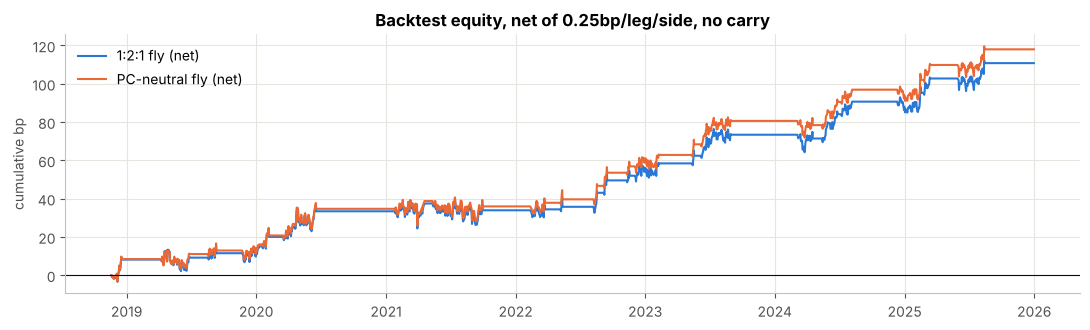

In [10]:
def carry_roll_bp(weights, entry_date, exit_date):
    # >>> CARRY / ROLL HOOK <<<  Return the carry + roll-down (bp, fly units) earned by holding `weights`
    # from entry_date to exit_date. Currently excluded.
    return 0.0


def backtest(z, levels, weight_fn):
    Y, zz, dates = levels.values, z.values, levels.index
    n = len(zz)
    daily = np.zeros(n)
    trades = []
    t = 0
    while t < n - EXEC_LAG:
        if np.isnan(zz[t]) or abs(zz[t]) <= Z_ENTRY:
            t += 1; continue
        side = -1 if zz[t] > 0 else 1                     # -1 = receive belly (profit if fly falls)
        wt = weight_fn(t)                                  # weights fixed at the signal date
        te = t + EXEC_LAG
        if te >= n - 1:
            break
        tx, reason = te + MAX_HOLD, "max hold"
        if tx > n - 1:
            tx, reason = n - 1, "open at end"
        for s in range(t + 1, n):
            if s + EXEC_LAG > tx:
                break
            if (zz[t] > 0 and zz[s] <= 0) or (zz[t] < 0 and zz[s] >= 0):
                tx, reason = s + EXEC_LAG, "reverted"; break
        fly = Y @ wt
        daily[te + 1: tx + 1] += side * np.diff(fly[te: tx + 1])
        cost = COST_BP_PER_LEG * np.abs(wt).sum()
        daily[te] -= cost; daily[tx] -= cost
        carry = carry_roll_bp(wt, dates[te], dates[tx])
        daily[tx] += carry
        gross = side * (fly[tx] - fly[te])
        trades.append(dict(entry=dates[te], exit=dates[tx], side="receive belly" if side < 0 else "pay belly",
                           z=zz[t], days=tx - te, gross_bp=gross, cost_bp=2 * cost, net_bp=gross - 2 * cost + carry, exit_reason=reason))
        t = tx
    return pd.DataFrame(trades), pd.Series(daily, index=dates)


def stats(tr, daily):
    eq = daily.cumsum()
    return pd.Series({"trades": len(tr), "hit rate": (tr.net_bp > 0).mean(), "avg hold (d)": tr.days.mean(),
                      "gross bp": tr.gross_bp.sum(), "costs bp": tr.cost_bp.sum(), "net bp": tr.net_bp.sum(),
                      "avg net/trade": tr.net_bp.mean(), "max DD bp": (eq - eq.cummax()).min()})


bt_dates = valid
z_bt, y_bt = res.loc[bt_dates, "z"], y.loc[bt_dates]
pos = {d: i for i, d in enumerate(y.index)}
tr_121, d_121 = backtest(z_bt, y_bt, lambda t: w.values)
tr_pcn, d_pcn = backtest(z_bt, y_bt, lambda t: pc_neutral(loadings[pos[bt_dates[t]]], TENORS, [5, 7, 10], 2).values)
summary = pd.DataFrame({"1:2:1 fly": stats(tr_121, d_121), "PC-neutral fly": stats(tr_pcn, d_pcn)}).T
display(summary.style.format({"trades": "{:.0f}", "hit rate": "{:.0%}", "avg hold (d)": "{:.1f}", "gross bp": "{:+.1f}",
                              "costs bp": "{:.1f}", "net bp": "{:+.1f}", "avg net/trade": "{:+.2f}", "max DD bp": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(d_121.cumsum(), color=C_BLUE, label="1:2:1 fly (net)")
ax.plot(d_pcn.cumsum(), color=C_ORANGE, label="PC-neutral fly (net)")
ax.axhline(0, color=C_INK, lw=0.8); ax.set_ylabel("cumulative bp"); ax.legend(loc="upper left")
ax.set_title(f"Backtest equity, net of {COST_BP_PER_LEG}bp/leg/side, no carry")
plt.tight_layout(); plt.show()

## 8. Stability check

This chart shows the change in today's fair value caused **only by re-estimating the PCA**: day *t*'s levels, scored with window *t*'s estimates and then with window *t−1*'s. Large jumps mean the fair value is driven by estimation noise rather than market moves. Dates above `FV_JUMP_BP` are flagged.

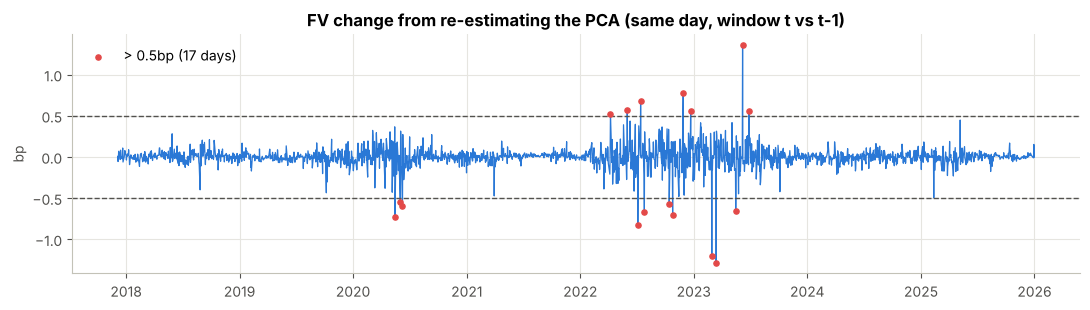

Re-estimation FV change: mean |Δ| = 0.067bp, max = 1.355bp, 17 of 2107 days flagged > 0.5bp
date
2022-07-26   -0.668
2022-10-14   -0.572
2022-10-25   -0.705
2022-11-28    0.771
2022-12-22    0.559
2023-02-28   -1.200
2023-03-14   -1.284
2023-05-16   -0.656
2023-06-07    1.355
2023-06-28    0.561


In [11]:
jump = (res["fv"] - res["fv_prev_est"]).dropna()
flags = jump[jump.abs() > FV_JUMP_BP]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(jump.index, jump.values, color=C_BLUE, lw=0.9)
ax.axhline(FV_JUMP_BP, color=C_MUTED, ls="--", lw=1); ax.axhline(-FV_JUMP_BP, color=C_MUTED, ls="--", lw=1)
ax.scatter(flags.index, flags.values, color=C_RED, s=14, zorder=3, label=f"> {FV_JUMP_BP}bp ({len(flags)} days)")
ax.set_ylabel("bp"); ax.legend(loc="upper left"); ax.set_title("FV change from re-estimating the PCA (same day, window t vs t-1)")
plt.tight_layout(); plt.show()
print(f"Re-estimation FV change: mean |Δ| = {jump.abs().mean():.3f}bp, max = {jump.abs().max():.3f}bp, "
      f"{len(flags)} of {len(jump)} days flagged > {FV_JUMP_BP}bp")
if len(flags):
    print(flags.round(3).tail(10).to_string())

## 9. Summary: today

In [12]:
today = res.index[-1]
rt, zt = res.loc[today, "resid"], res.loc[today, "z"]
call = ("CHEAP belly: receive 7y vs 5y/10y" if zt > Z_ENTRY else "RICH belly: pay 7y vs 5y/10y" if zt < -Z_ENTRY
        else f"no signal (|z| <= {Z_ENTRY:g}); leaning {'cheap' if rt > 0 else 'rich'}")
print(f"Date            : {today:%Y-%m-%d}")
print(f"5s7s10s fly     : {res.loc[today, 'fly']:.2f} bp")
print(f"PCA fair value  : {res.loc[today, 'fv']:.2f} bp")
print(f"Residual        : {rt:+.2f} bp  (positive = belly cheap)")
print(f"z (sd / MAD)    : {zt:+.2f} / {res.loc[today, 'z_mad']:+.2f}")
print(f"Call            : {call}")
print(f"Half-life       : {half_life:.1f} business days (AR(1) phi {phi:.3f}, ADF p {adf_p:.4f})")
print(f"PC-neutral 3-leg: " + ", ".join(f"{t}y {w_neutral3[t]:+.3f}" for t in [5, 7, 10])
      + f"  (PC3 exposure {w_neutral3 @ E_last[:, 2]:+.3f})")
print(f"PC-neutral 4-leg: " + ", ".join(f"{t}y {w_neutral4[t]:+.3f}" for t in [5, 7, 10, 30]))
print("\nSimulated data: plumbing test only. No carry/roll in P&L yet.")

Date            : 2025-12-31
5s7s10s fly     : 6.17 bp
PCA fair value  : 2.32 bp
Residual        : +3.85 bp  (positive = belly cheap)
z (sd / MAD)    : +0.57 / +0.57
Call            : no signal (|z| <= 2); leaning cheap
Half-life       : 8.4 business days (AR(1) phi 0.921, ADF p 0.0000)
PC-neutral 3-leg: 5y -1.121, 7y +2.000, 10y -0.885  (PC3 exposure +0.200)
PC-neutral 4-leg: 5y -0.901, 7y +2.000, 10y -1.215, 30y +0.159

Simulated data: plumbing test only. No carry/roll in P&L yet.
